# Thực nghiệm lọc cộng tác (Collaborative Filtering)

So sánh 3 cách gợi ý sách trên bộ dữ liệu Goodbooks-10k:

- Gợi ý theo độ phổ biến (baseline)
- User-based CF
- Item-based CF

Đánh giá bằng Precision@K và Recall@K với K = 5, 10, 20.

**Cách chạy**

- Google Colab: mở link https://colab.research.google.com/github/NguyenHuyBao11-05/TieuLuan_Web_TMDT/blob/main/docs/recommendation/cf_experiment.ipynb, chọn *Runtime > Run all*. Dữ liệu sẽ được tải tự động.
- Trên máy: cài `pip install numpy pandas matplotlib notebook`, mở thư mục `docs/recommendation` rồi chạy `jupyter notebook cf_experiment.ipynb`. Nếu chưa có thư mục `data/` thì notebook cũng tự tải về.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("data")
DATA_URL = "https://raw.githubusercontent.com/zygmuntz/goodbooks-10k/master/"

NUM_USERS = 2000
NUM_BOOKS = 2000
MIN_RATINGS_PER_USER = 20
NEIGHBORS = 30
TEST_RATIO = 0.2
LIKE_THRESHOLD = 4
K_VALUES = [5, 10, 20]
SEED = 42

## 1. Tải dữ liệu

Goodbooks-10k gồm khoảng 6 triệu lượt đánh giá (1 - 5 sao) của 53.424 người dùng cho 10.000 cuốn sách trên Goodreads.

- `ratings.csv`: user_id, book_id, rating
- `books.csv`: thông tin sách (tên, tác giả, ...)

In [2]:
DATA_DIR.mkdir(exist_ok=True)
for name in ["ratings.csv", "books.csv"]:
    path = DATA_DIR / name
    if not path.exists():
        print("Đang tải", name)
        urlretrieve(DATA_URL + name, path)

ratings_all = pd.read_csv(DATA_DIR / "ratings.csv")
books = pd.read_csv(DATA_DIR / "books.csv", usecols=["book_id", "title", "authors"])

print("Số lượt đánh giá:", len(ratings_all))
print("Số người dùng:", ratings_all["user_id"].nunique())
print("Số sách:", ratings_all["book_id"].nunique())
ratings_all.head()

Số lượt đánh giá: 5976479
Số người dùng: 53424
Số sách: 10000


,user_id,book_id,rating
0,1,258,5
1,2,4081,4
2,2,260,5
3,2,9296,5
4,2,2318,3


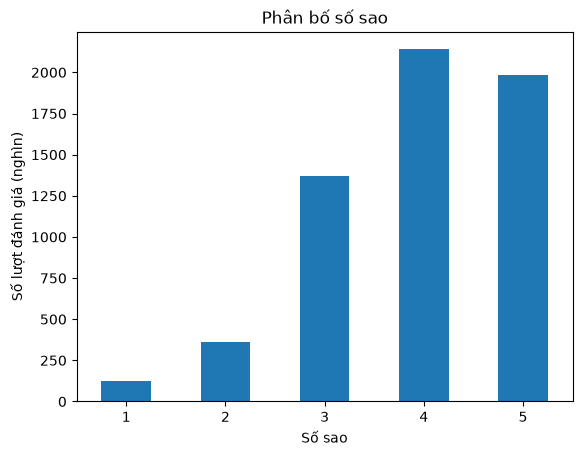

In [3]:
rating_counts = ratings_all["rating"].value_counts().sort_index() / 1000
rating_counts.plot(kind="bar", title="Phân bố số sao", rot=0)
plt.xlabel("Số sao")
plt.ylabel("Số lượt đánh giá (nghìn)")
plt.show()

## 2. Lấy mẫu dữ liệu

Dữ liệu đầy đủ khá lớn nên em lấy mẫu để chạy nhanh trên máy cá nhân:

- 2.000 cuốn sách có nhiều lượt đánh giá nhất
- 2.000 người dùng chọn ngẫu nhiên trong những người đã đánh giá ít nhất 20 cuốn (trong 2.000 cuốn trên)

In [4]:
top_books = ratings_all["book_id"].value_counts().head(NUM_BOOKS).index
ratings = ratings_all[ratings_all["book_id"].isin(top_books)]

user_counts = ratings["user_id"].value_counts()
active_users = user_counts[user_counts >= MIN_RATINGS_PER_USER].index
rng = np.random.default_rng(SEED)
sample_users = rng.choice(active_users, size=NUM_USERS, replace=False)
ratings = ratings[ratings["user_id"].isin(sample_users)]

print("Số lượt đánh giá sau khi lấy mẫu:", len(ratings))

Số lượt đánh giá sau khi lấy mẫu: 153405


## 3. Chia tập train / test

Với mỗi người dùng, giữ lại ngẫu nhiên 20% số đánh giá làm tập test. Thuật toán chỉ được nhìn thấy 80% còn lại, sau đó kiểm tra xem nó có gợi ý trúng những cuốn bị giấu đi hay không.

In [5]:
test = ratings.groupby("user_id").sample(frac=TEST_RATIO, random_state=SEED)
train = ratings.drop(test.index)

print("Train:", len(train))
print("Test:", len(test))

Train: 122735
Test: 30670


## 4. Ma trận người dùng - sách

Mỗi dòng là một người dùng, mỗi cột là một cuốn sách, giá trị là số sao. Ô bằng 0 nghĩa là người dùng chưa đánh giá cuốn đó.

In [6]:
user_ids = sorted(train["user_id"].unique())
book_ids = sorted(train["book_id"].unique())
user_index = {user_id: i for i, user_id in enumerate(user_ids)}
book_index = {book_id: i for i, book_id in enumerate(book_ids)}

matrix = np.zeros((len(user_ids), len(book_ids)), dtype=np.float32)
rows = train["user_id"].map(user_index).to_numpy()
cols = train["book_id"].map(book_index).to_numpy()
matrix[rows, cols] = train["rating"].to_numpy()

print("Kích thước ma trận:", matrix.shape)
print(f"Độ thưa: {1 - (matrix > 0).mean():.2%} ô trống")

Kích thước ma trận: (2000, 2000)
Độ thưa: 96.93% ô trống


Tập test chỉ giữ những cuốn người dùng **thích** (từ 4 sao trở lên). Đây là những cuốn mà ta mong thuật toán gợi ý được.

In [7]:
liked = test[(test["rating"] >= LIKE_THRESHOLD) & test["book_id"].isin(book_index.keys())]
test_liked = {}
for user_id, group in liked.groupby("user_id"):
    test_liked[user_index[user_id]] = {book_index[b] for b in group["book_id"]}

print("Số người dùng dùng để đánh giá:", len(test_liked))

Số người dùng dùng để đánh giá: 1997


## 5. Độ tương đồng cosine

Hai vector $a$ và $b$ càng giống nhau thì góc giữa chúng càng nhỏ, cosine càng gần 1:

$$\text{sim}(a, b) = \frac{a \cdot b}{\|a\| \, \|b\|}$$

- User-based: so sánh 2 dòng của ma trận (2 người dùng)
- Item-based: so sánh 2 cột của ma trận (2 cuốn sách)

In [8]:
def cosine_similarity(vectors):
    norms = np.linalg.norm(vectors, axis=1, keepdims=True)
    norms[norms == 0] = 1
    normalized = vectors / norms
    return normalized @ normalized.T

## 6. Ba phương pháp gợi ý

**Baseline - độ phổ biến:** ai cũng được gợi ý những cuốn có nhiều người đánh giá nhất.

**User-based CF:** tìm 30 người dùng giống $u$ nhất (láng giềng $N(u)$), cuốn sách nào được các láng giềng đánh giá cao thì gợi ý cho $u$:

$$\text{score}(u, i) = \sum_{v \in N(u)} \text{sim}(u, v) \cdot r_{v,i}$$

**Item-based CF:** cuốn sách $i$ được điểm cao nếu nó giống những cuốn $u$ đã đánh giá cao:

$$\text{score}(u, i) = \sum_{j} r_{u,j} \cdot \text{sim}(j, i)$$

In [9]:
def popularity_scores(matrix):
    popularity = (matrix > 0).sum(axis=0).astype(np.float32)
    return np.tile(popularity, (matrix.shape[0], 1))


def user_based_scores(matrix):
    similarity = cosine_similarity(matrix)
    np.fill_diagonal(similarity, 0)
    scores = np.zeros_like(matrix)
    for u in range(matrix.shape[0]):
        neighbors = np.argsort(similarity[u])[::-1][:NEIGHBORS]
        scores[u] = similarity[u, neighbors] @ matrix[neighbors]
    return scores


def item_based_scores(matrix):
    similarity = cosine_similarity(matrix.T)
    np.fill_diagonal(similarity, 0)
    return matrix @ similarity, similarity


item_scores, item_similarity = item_based_scores(matrix)
methods = {
    "Phổ biến (baseline)": popularity_scores(matrix),
    "User-based CF": user_based_scores(matrix),
    "Item-based CF": item_scores,
}

## 7. Đánh giá

Với mỗi người dùng, lấy K cuốn có điểm cao nhất (bỏ qua những cuốn đã đánh giá trong train), rồi so với những cuốn họ thích trong tập test:

$$\text{Precision@K} = \frac{\text{số cuốn gợi ý trúng}}{K} \qquad \text{Recall@K} = \frac{\text{số cuốn gợi ý trúng}}{\text{số cuốn thích trong tập test}}$$

Kết quả là trung bình trên tất cả người dùng.

In [10]:
def recommend_top_k(scores, matrix, k):
    scores = scores.copy()
    scores[matrix > 0] = -np.inf
    return np.argsort(-scores, axis=1)[:, :k]


def evaluate(top_items, test_liked, k):
    precisions = []
    recalls = []
    for u, liked_books in test_liked.items():
        hits = len(set(top_items[u, :k]) & liked_books)
        precisions.append(hits / k)
        recalls.append(hits / len(liked_books))
    return np.mean(precisions), np.mean(recalls)


top_items_by_method = {}
results = []
for name, scores in methods.items():
    top_items = recommend_top_k(scores, matrix, max(K_VALUES))
    top_items_by_method[name] = top_items
    row = {"Phương pháp": name}
    for k in K_VALUES:
        precision, recall = evaluate(top_items, test_liked, k)
        row[f"P@{k}"] = round(precision, 4)
        row[f"R@{k}"] = round(recall, 4)
    results.append(row)

results = pd.DataFrame(results).set_index("Phương pháp")
results

,P@5,R@5,P@10,R@10,P@20,R@20
Phương pháp,,,,,,
Phổ biến (baseline),0.1003,0.0456,0.0778,0.0712,0.0612,0.1102
User-based CF,0.2650,0.1310,0.1994,0.1936,0.1417,0.2725
Item-based CF,0.2673,0.1321,0.1960,0.1926,0.1405,0.2746


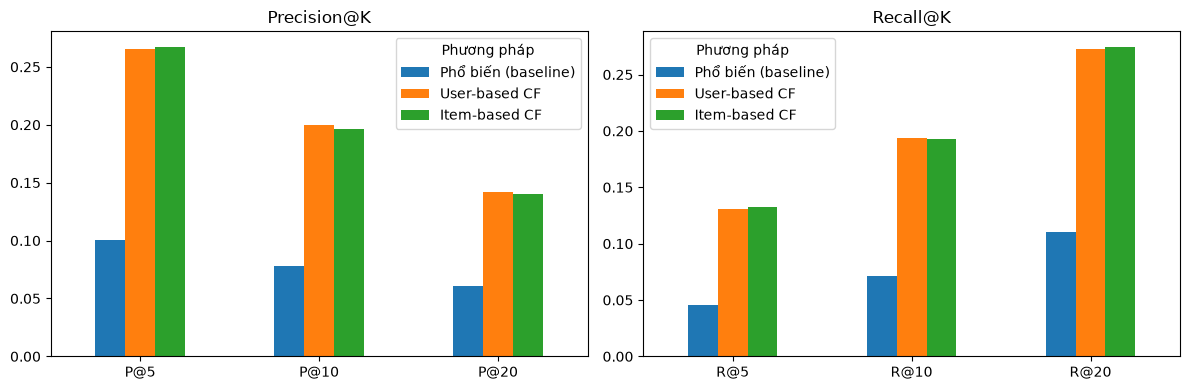

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
results[[f"P@{k}" for k in K_VALUES]].T.plot(kind="bar", ax=axes[0], title="Precision@K", rot=0)
results[[f"R@{k}" for k in K_VALUES]].T.plot(kind="bar", ax=axes[1], title="Recall@K", rot=0)
plt.tight_layout()
plt.show()

## 8. Ví dụ gợi ý cho một người dùng

In [12]:
titles = books.set_index("book_id")["title"]
example_user = user_ids[0]
u = user_index[example_user]

print("Người dùng", example_user)
print("Sách đã đánh giá cao:")
for i in np.argsort(-matrix[u])[:5]:
    print(f"  {int(matrix[u, i])} sao - {titles[book_ids[i]]}")

print("Sách được gợi ý (Item-based):")
for i in top_items_by_method["Item-based CF"][u, :5]:
    print("  ", titles[book_ids[i]])

Người dùng 16
Sách đã đánh giá cao:
  5 sao - The Prince and the Pauper
  5 sao - I, Robot (Robot #0.1)
  5 sao - A Farewell to Arms
  5 sao - Blindness
  5 sao - The Good Earth (House of Earth, #1)
Sách được gợi ý (Item-based):
   1984
   To Kill a Mockingbird
   The Great Gatsby
   Of Mice and Men
   Romeo and Juliet


## 9. Sách liên quan

Ma trận độ tương đồng giữa các sách của Item-based còn dùng được cho mục "Sách liên quan" ở trang chi tiết sách.

In [13]:
def related_books(title, n=5):
    book_id = books.loc[books["title"] == title, "book_id"].iloc[0]
    i = book_index[book_id]
    similar = np.argsort(-item_similarity[i])[:n]
    return pd.DataFrame({
        "Sách": [titles[book_ids[j]] for j in similar],
        "Độ tương đồng": item_similarity[i, similar].round(3),
    })


related_books("Harry Potter and the Sorcerer's Stone (Harry Potter, #1)")

,Sách,Độ tương đồng
0,Harry Potter and the Prisoner of Azkaban (Harr...,0.541
1,Harry Potter and the Deathly Hallows (Harry Po...,0.514
2,Harry Potter and the Half-Blood Prince (Harry ...,0.513
3,Harry Potter and the Goblet of Fire (Harry Pot...,0.508
4,Harry Potter and the Chamber of Secrets (Harry...,0.501


## 10. Nhận xét

- Cả hai cách lọc cộng tác đều tốt hơn rõ rệt so với gợi ý theo độ phổ biến: với 10 cuốn gợi ý, CF trúng khoảng 2 cuốn, baseline chưa tới 1 cuốn (gấp khoảng 2,5 lần).
- User-based và Item-based cho kết quả gần bằng nhau.
- Em chọn Item-based để đưa vào website vì độ tương đồng giữa các sách ít thay đổi, có thể tính trước theo lô và dùng lại cho mục "Sách liên quan".
- Dữ liệu rất thưa (gần 97% ô trống) nên Precision không cao. Các thực nghiệm tiếp theo: chuẩn hóa điểm theo trung bình từng người dùng, thử số láng giềng khác nhau, kết hợp thêm dữ liệu hành vi (xem, thêm giỏ, mua).